### Welcome to Microlensing for Babies, for Toddlers.  

So you've fit some Beginner Tier events. Congrats!

You are now fit to fit some Machine Learning Tier events. There are some key differences to the process, but we'll go through them step by step!

In [1]:
%pip install -U microlens_submit
%pip install -U RTModel==3.3
%pip install -U jacscanomaly
%pip install -U microjax
%pip uninstall -U pyAethra
%pip install -U pyAethra

%pip install seaborn


[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.

[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.

[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.

[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.

Usage:   
  /opt/conda/envs/rges-pit-dc/bin/python -m pip uninstall [options] <package> ...
  /opt/conda/envs/rges-pit-dc/bin/python -m pip uninstall [options] -r <requirements file> ...

no such option: -U
Note: you may need to restart the kernel to use updated packages.

[notice] A new release of

In [25]:
# system imports
import os
import time
import sys
from pathlib import Path
from tqdm import tqdm
import glob 

# data access imports
from huggingface_hub import hf_hub_download
import pandas as pd
from astropy.coordinates import SkyCoord
import astropy.units as u

# display imports
from IPython.display import HTML

# multiprocessing imports
import multiprocessing as mp
from multiprocessing.pool import ThreadPool

# data challenge imports
import microlens_submit
#import MulensModel
import emcee
#from pyLIMA.pyLIMASS import SourceLensProbabilities
import RTModel

# data analysis/visualization imports
import numpy as np
import matplotlib.pyplot as plt

# detection packages
from pyAethra import load_config, load_and_run
from jacscanomaly import CandidateCriteria, Finder, FinderConfig

root_dir = '/home/mldc-ipacpeople-admin/teams/mldc-ipacpeople/'

In [3]:
import pyAethra
print(pyAethra.__version__)
import jacscanomaly
print(jacscanomaly.__version__)
print(sys.version)
print(np.__version__)


0.1.2
1.0.4
3.11.14 | packaged by conda-forge | (main, Jan 26 2026, 23:48:32) [GCC 14.3.0]
2.4.1


In [4]:
# following extra instructions for data download from https://huggingface.co/datasets/RGES-PIT/MachineLearning
%pip install datasets pandas pyarrow duckdb huggingface_hub
#export HF_TOKEN="hf_your_token_here"
#%pip install --upgrade huggingface_hub

/opt/conda/envs/rges-pit-dc/lib/python3.11/pty.py:89: RuntimeWarning: os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.
  pid, fd = os.forkpty()



[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


When you run the following cell the first time after starting your kernel, you will get an error saying "ValueError: pyarrow.lib.Array size changed, may indicate binary incompatibility. Expected 80 from C header, got 72 from PyObject". 

You must restart the kernel (Kernel > Restart Kernel) and re-run everything from the top, and then it should work. 

In [5]:
from datasets import load_dataset
import os

os.environ["HF_TOKEN"] = "hf_your_token_here" # generate your own huggingface token if you are planning to run tons of events; for now, this is fine as-is

token = os.environ.get("HF_TOKEN")
assert token, "Set HF_TOKEN environment variable first"

dataset_name = "RGES-PIT/MachineLearning"

# Load metadata and epochs tables (which fit easily in RAM)
meta_df = load_dataset(dataset_name, "metadata", split="train", token=token).to_pandas()
epochs_df = load_dataset(dataset_name, "epochs", split="train", token=token).to_pandas()

print(f"Metadata     : {meta_df.shape[0]:,} rows")
print(f"Epochs       : {epochs_df.shape[0]:,} rows")


Metadata     : 377,999 rows
Epochs       : 98,974 rows


In [6]:
meta_df

,name,event_id,sim_label,SubRun,Field,EventID,final_weight,ObsGroup_0_chi2,t0lens1,tE_ref,...,Source_Fe_H,Source2_Mass,Source2_Dist,Source2_Teff,Source2_logg,Source2_Fe_H,is_out_of_season,extinction_F146,extinction_F087,extinction_F213
0,RMDC26_003000,3000,RMDC26_1S1L_ML,0.0,633.0,1936.0,0.012366,66.744210,2.462736e+06,3.585315,...,0.319104,NaN,NaN,NaN,NaN,NaN,False,2.061971,5.147735,0.692188
1,RMDC26_003016,3016,RMDC26_1S1L_ML,0.0,718.0,7002.0,0.021194,13124.511426,2.462735e+06,0.214467,...,0.120387,NaN,NaN,NaN,NaN,NaN,False,0.483870,1.207987,0.162431
2,RMDC26_003032,3032,RMDC26_1S1L_ML,0.0,874.0,572.0,0.016154,3438.811691,2.461841e+06,0.051493,...,-0.556216,NaN,NaN,NaN,NaN,NaN,False,0.848105,2.117306,0.284703
3,RMDC26_003048,3048,RMDC26_1S1L_ML,2.0,0.0,4028.0,0.013090,379.330478,2.461504e+06,14.050508,...,0.080757,NaN,NaN,NaN,NaN,NaN,False,3.180586,7.940372,1.067699
4,RMDC26_003064,3064,RMDC26_1S1L_ML,1.0,21.0,7425.0,0.034964,103.546626,2.461713e+06,36.203618,...,-0.110039,NaN,NaN,NaN,NaN,NaN,True,2.581654,6.445132,0.866642
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
377994,RMDC26_384935,384935,RMDC26_2S2L_ML,1.0,918.0,81.0,0.179904,1774.770527,2.462784e+06,9.992783,...,0.347771,0.508594,8.585019,3642.0633,4.780081,0.347771,False,0.675996,1.687633,0.226927
377995,RMDC26_384951,384951,RMDC26_2S2L_ML,9.0,839.0,135.0,0.061461,223.086016,2.461851e+06,18.258675,...,0.251984,0.149794,8.099978,2853.6476,5.120895,0.251984,False,0.631576,1.576737,0.212015
377996,RMDC26_384967,384967,RMDC26_2S2L_ML,5.0,49.0,139.0,0.002384,11644.003410,2.461874e+06,3.280384,...,0.464354,NaN,NaN,NaN,NaN,NaN,False,0.691602,1.726592,0.232166
377997,RMDC26_384983,384983,RMDC26_2S2L_ML,5.0,874.0,411.0,0.085583,4561.931445,2.461884e+06,8.112539,...,-0.322607,0.446117,9.057338,3819.0020,4.833098,-0.322607,True,1.476690,3.686576,0.495714


In [7]:
epochs_df

,epoch_id,bjd,obs_x,obs_y,obs_z
0,0,2.461448e+06,-0.787730,0.613210,0.005062
1,1,2.461448e+06,-0.790863,0.609200,0.005066
2,2,2.461448e+06,-0.793980,0.605173,0.005070
3,3,2.461449e+06,-0.800147,0.597080,0.005074
4,4,2.461449e+06,-0.803200,0.593010,0.005076
...,...,...,...,...,...
98969,98969,2.462597e+06,-0.974904,-0.261480,-0.004752
98970,98970,2.462602e+06,-0.950344,-0.343808,-0.004996
98971,98971,2.462607e+06,-0.918830,-0.423583,-0.005084
98972,98972,2.462612e+06,-0.880622,-0.500253,-0.005014


Let's query a single light curve first

In [8]:
import duckdb
from huggingface_hub import HfFileSystem
import os

token = os.environ.get("HF_TOKEN")
con = duckdb.connect()
con.register_filesystem(HfFileSystem(token=token))

obs_p = "hf://datasets/RGES-PIT/MachineLearning/RMDC26_ML_Data_obs.parquet"
meta_p = "hf://datasets/RGES-PIT/MachineLearning/RMDC26_ML_Data_meta.parquet"
epoch_p = "hf://datasets/RGES-PIT/MachineLearning/RMDC26_ML_Data_epoch.parquet"

event_id = 3000

# Reconstruct a single event's lightcurve
event_obs = con.execute(f"""
    SELECT 
        o.event_id,
        m.name,
        e.bjd,
        o.filt,
        o.flux_uJy,
        m.tE_helio,
        m.sim_label
    FROM '{obs_p}' o
    JOIN '{epoch_p}' e ON o.epoch_id = e.epoch_id
    JOIN '{meta_p}' m ON o.event_id = m.event_id
    WHERE o.event_id = {event_id}
    ORDER BY e.bjd
""").df()

print(f"Event {event_id}: {event_obs['name'].iloc[0]} ({event_obs['sim_label'].iloc[0]})")
print(f"  {len(event_obs):,} observations")
print(f"  Einstein timescale tE_helio = {abs(event_obs['tE_helio'].iloc[0]):.2f} days")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Event 3000: RMDC26_003000 (RMDC26_1S1L_ML)
  49,488 observations
  Einstein timescale tE_helio = 3.55 days


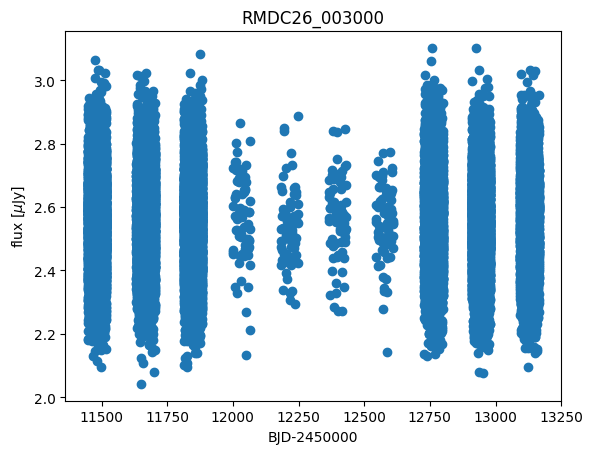

In [9]:
event_obs['bjd-2450000'] = event_obs['bjd'] - 2450000

event_obs_filt = event_obs.loc[event_obs['filt']=='F146']
plt.scatter(event_obs_filt['bjd-2450000'], event_obs_filt['flux_uJy'])
plt.ylabel(r'flux [$\mu$Jy]')
plt.xlabel('BJD-2450000')
plt.title(f"{event_obs['name'].iloc[0]}")
plt.show()

Huzzah. So, off-screen, I have run the RGES PIT detection pipleine (pyAethra v0.1.2 and jacscanomaly v0.5.1) on the ML Tier true 2L1S events, keeping only those events whose true t0 falls in Season 1, or 30 days afterward (for buffer). 

My intention is to model these events for detection efficiency. By modeling 10 of these events, you'll be helping me to that end!

In [10]:
season1_detections = pd.read_csv(root_dir+'data/1s2l_detected_season1.csv')
season1_detections

,event_id,label,t0,u0,tE,t0_anomaly,jacscanomaly_score
0,319702,microlensing,11459.421292,1.999941,5.842098,2.461488e+06,105.539152
1,309512,microlensing,11516.916088,0.293545,7.244630,2.461516e+06,124519.322927
2,334405,microlensing,11497.349634,2.000000,100.000000,2.461448e+06,14.785119
3,327675,microlensing,11482.191935,0.019395,10.116765,2.461509e+06,114.128774
4,338049,microlensing,11450.413950,0.426479,3.304466,2.461502e+06,55697.723817
...,...,...,...,...,...,...,...
2754,330571,microlensing,11449.902795,1.888197,10.993514,2.461452e+06,NaN
2755,321688,flat,NaN,NaN,NaN,NaN,NaN
2756,319715,flat,NaN,NaN,NaN,NaN,NaN
2757,318322,microlensing,11442.780338,0.158036,99.999970,2.461452e+06,NaN


You've already modeled, so let's skip the step-by-step and wrap everything up in a neat little function.

**SET YOUR EVENT FOLDER SO YOU DON'T OVERWRITE OTHER PEOPLE'S WORK**

In [13]:
event_data_me = 'event_data_chris' # change this, please!

In [14]:
def model(event_id, lc_data):

    # convert BJD so it's easier to work with
    lc_data['bjd-2450000'] = lc_data['bjd']-2450000
    
    # create event directory in the format RTModel wants
    #event_data_me = 'event_data_baby'
    new_event_dir = root_dir + '/' + event_data_me + '/event_' + event_id
    try:
        os.mkdir(new_event_dir)
    except Exception as e:
        pass
    # create /Data/ directory in your event directory. This is necessary for RTModel, which is very exacting about your event directory layout!
    try:
        os.mkdir(new_event_dir + '/Data/')
    except Exception as e:
        pass

    # set up filters
    for filt in filters:
        lc_data_filt = lc_data.loc[lc_data['filt']==filt]#[time_mask]
        lc_data_dat = pd.DataFrame({'Flux': lc_data_filt['flux_uJy'], 'err': lc_data_filt['flux_err_uJy'], 'HJD-2450000': lc_data_filt['bjd-2450000']})
        if filt=='F087':
            dat_filepath = new_event_dir + '/Data/RomanZ087sat2.dat'
        elif filt=='F146':
            dat_filepath = new_event_dir + '/Data/RomanW146sat1.dat'
        elif filt=='F213':
            dat_filepath = new_event_dir + '/Data/RomanK213sat3.dat'
        with open(dat_filepath, "w", encoding="utf-8") as f:
            f.write("# Flux err HJD-2450000\n")
            lc_data_dat.to_csv(f, sep=' ', header=None, index=False)

    # add coordinates in Data/ dir too     
    coords = SkyCoord(ra=lc_data_filt['ra_deg'].values[0]*u.degree, dec=lc_data_filt['dec_deg'].values[0]*u.degree, frame='icrs')
    ra_hms = coords.ra.to_string(unit=u.hourangle, sep=':', pad=True)
    dec_dms = coords.dec.to_string(sep=':', pad=True)
    coord_filepath = new_event_dir + '/Data/event.coordinates'
    with open(coord_filepath, "w", encoding="utf-8") as cf:
        cf.write(f"{ra_hms} {dec_dms}")

    # add limb darkening file in Data/
    limb_dark_filepath = new_event_dir + '/Data/LimbDarkening.txt'
    with open(limb_dark_filepath, "w", encoding="utf-8") as ld:
        ld.write("0.33 \n0.4532 \n0.251")

    # RTModel
    rtm = RTModel.RTModel(new_event_dir) # if I do rtm.run(), this argument is empty (spoiler: we're not doing rtm.run()
    rtm.set_satellite_dir(root_dir + '/satellitedir')
    #rtm.config_Reader(otherseasons=-1) # throw away all other seasons; this is reasonable because seasons are separated by ~half a year
    rtm.config_Reader(otherseasons=0, binning=1000000, renormalize=0) # there is a risk that long-duration events are more subject to parallax, which could affect planet recovery (slanty-->think it's a planet?)
    # rtm.config_InitCond(usesatellite = 1)
    rtm.config_InitCond(usesatellite = 1, peakthreshold=5) # usesatellite=1: space-based; usesatellite=0: ground-based; default peakthreshold is 10, but PIT uses 5, which is slower but better for recovery
    rtm.Reader()
    rtm.InitCond()

    rtm.run(root_dir + '/' + event_data_me + '/event_'+event_id)
    rtm.Finalizer()

    return
                    

In [23]:
# a bit of mise en place
event_ids = np.sort(season1_detections['event_id'])[:10]
filters = ['F087', 'F146', 'F213'] 
print(event_ids)

[306462 306493 306519 306543 306559 306569 306575 306577 306579 306583]


In case your kernel or the server dies partway through, since each event takes a while to model, here is a cell of code to skip events you have already modeled. 

In [33]:
events_dir = root_dir + event_data_me + "/"
done_events = []
for f in np.sort(glob.glob(events_dir+"/*")):
    event_id = int(f.removeprefix(events_dir+"event_"))
    if event_id < 300000:
        continue

    event_dir = events_dir + 'event_' + "{:04d}/".format(event_id)

    if os.path.isdir(event_dir+'FinalModels/') == True:
        done_events.append(event_id)

event_ids_not_done = np.setdiff1d(event_ids, np.array(done_events))
print(event_ids_not_done)

[306462 306519 306543 306559 306575 306579 306583]


In [20]:
for event_id in tqdm(event_ids): # or event_ids_not_done
    # grab light curve, as shown above
    event_id = str(event_id)
    event_obs = con.execute(f"""
        SELECT 
            o.event_id,
            m.name,
            e.bjd,
            o.filt,
            o.flux_uJy,
            o.flux_err_uJy,
            m.tE_helio,
            m.sim_label,
            m.ra_deg,
            m.dec_deg
        FROM '{obs_p}' o
        JOIN '{epoch_p}' e ON o.epoch_id = e.epoch_id
        JOIN '{meta_p}' m ON o.event_id = m.event_id
        WHERE o.event_id = {event_id}
        ORDER BY e.bjd
    """).df()
    
    print(f"Event {event_id}: {event_obs['name'].iloc[0]} ({event_obs['sim_label'].iloc[0]})")

    # model!
    print("modeling event!")
    model(event_id, event_obs)
    

  0%|          | 0/10 [00:00<?, ?it/s]

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Event 319702: RMDC26_319702 (RMDC26_1S2L_ML)
modeling event!
*********************
****   RTModel   ****
*********************
Event name: /teams/mldc-ipacpeople/event_data_chris/event_319702
Number of processors: 2
- Launching: Reader
  Pre-processing data...
  Found ground telescopes:  []
  Found satellite 1:  ['RomanW146sat1']
  Found satellite 2:  ['RomanZ087sat2']
  Found satellite 3:  ['RomanK213sat3']
  OK
- Launching: InitCond
  Setting initial conditions...
Peaks:  
11463.5800 [6.1773]
12946.6100 [6.0388]

  OK
o Mon Nov  9 23:47:12 2026
- Analyzing event:  /teams/mldc-ipacpeople/event_data_chris/event_319702
- Launching: Reader
  Pre-processing data...
  Found ground telescopes:  []
  Found satellite 1:  ['RomanW146sat1']
  Found satellite 2:  ['RomanZ087sat2']
  Found satellite 3:  ['RomanK213sat3']
  OK
o Mon Nov  9 23:47:12 2026
- Launching: InitCond
  Setting initial conditions...
Peaks:  
11463.5800 [6.1773]
12946.6100 [6.0388]

  OK
o Mon Nov  9 23:47:12 2026
- Single-l

  0%|          | 0/10 [00:13<?, ?it/s]


KeyboardInterrupt: 